In [1]:
import time
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

MU = 5.0  # nonlinearity factor
X0 = 1.0   # initial position x(0)
V0 = 0.0   # initial velocity x'(0)

PERIOD_MARGIN = 1.15
ROUGH_PERIOD_FACTOR = 1.614
N_PERIODS_SETTLE = 4

WINDOW_SIZE = 2.0  # length of each time-marching window (uniform, unlike the adaptive script)

LAYERS = (1, 32, 32, 32, 32, 1)  # shared network depth/width
N_COLLOCATION_PER_WINDOW = 2000
ADAM_EPOCHS = 3000
ADAM_LR = 1e-3
LBFGS_MAX_ITER = 2000
PRINT_EVERY = 500

Using device: cuda


In [2]:
def van_der_pol_rhs(t, y, mu=MU):
    x, v = y
    return [v, mu * (1 - x ** 2) * v - x]

def estimate_vdp_period(mu, x0=X0, v0=V0, rough_factor=ROUGH_PERIOD_FACTOR, n_settle=N_PERIODS_SETTLE):
    rough_T = rough_factor * mu
    t_span = n_settle * max(rough_T, 5.0)
    def event_peak(t, y):
        return y[1]
    event_peak.direction = -1

    sol = solve_ivp(
        lambda t, y: van_der_pol_rhs(t, y, mu=mu),
        [0.0, t_span], [x0, v0],
        events=event_peak, rtol=1e-10, atol=1e-12, max_step=0.05,
    )
    peak_times = sol.t_events[0]
    if len(peak_times) < 3:
        print(f"[period detection] not enough peaks found, falling back to rough estimate {rough_T:.3f}")
        return rough_T
    period = peak_times[-1] - peak_times[-2]
    return period

vdp_period = estimate_vdp_period(MU)
T_FINAL = float(PERIOD_MARGIN * vdp_period)
print(f"Detected VdP period at mu={MU}: {vdp_period:.4f}  ->  T_FINAL = {T_FINAL:.4f}")

N_WINDOWS = int(round(T_FINAL / WINDOW_SIZE))
window_edges = np.array([w * WINDOW_SIZE for w in range(N_WINDOWS + 1)])
window_edges[-1] = T_FINAL  # snap the last edge exactly to T_FINAL in case of rounding
window_widths = np.diff(window_edges)
print(f"Uniform window edges (t): {np.round(window_edges, 3)}")
print(f"Window widths: {np.round(window_widths, 3)}")
print(f"Window count: {N_WINDOWS}")

Detected VdP period at mu=5.0: 11.6122  ->  T_FINAL = 13.3541
Uniform window edges (t): [ 0.     2.     4.     6.     8.    10.    12.    13.354]
Window widths: [2.    2.    2.    2.    2.    2.    1.354]
Window count: 7


In [3]:
class BasePINN(nn.Module):
    # Shared architecture skeleton: encode_input() + trunk_forward()

    def __init__(self):
        super().__init__()

    def encode_input(self, t):
        raise NotImplementedError

    def trunk_forward(self, encoded):
        raise NotImplementedError

    def forward(self, t):
        return self.trunk_forward(self.encode_input(t))

    @staticmethod
    def init_linear(linear):
        nn.init.xavier_normal_(linear.weight)
        nn.init.zeros_(linear.bias)

In [4]:
class VanillaPINN(BasePINN):
    # Standard PINN architecture
    def __init__(self, t_start, window_size, layers=LAYERS):
        super().__init__()
        self.t_start = t_start
        self.window_size = window_size
        self.trunk = nn.ModuleList()
        for i in range(len(layers) - 1):
            linear = nn.Linear(layers[i], layers[i + 1])
            self.init_linear(linear)
            self.trunk.append(linear)
        self.activation = torch.tanh

    def encode_input(self, t):
        tau = t - self.t_start
        return (2.0 * tau / self.window_size) - 1.0

    def trunk_forward(self, encoded):
        out = encoded
        for layer in self.trunk[:-1]:
            out = self.activation(layer(out))
        return self.trunk[-1](out)

In [5]:
class WindowPINN(nn.Module):
    """
    Time-marching wrapper, wraps base architecture (VanillaPINN) and enforces this window's initial condition exactly:
    x(t) = x0_local + v0_local * tau + tau^2 * base_model(t)
    """
    def __init__(self, base_model, t_start, window_size, x0_local, v0_local):
        super().__init__()
        self.base_model = base_model
        self.t_start = t_start
        self.window_size = window_size
        self.x0_local = x0_local
        self.v0_local = v0_local

    def forward(self, t):
        tau = t - self.t_start
        n_raw = self.base_model(t)
        return self.x0_local + self.v0_local * tau + (tau ** 2) * n_raw

In [6]:
def physics_residual(model, t, mu=MU):
    x = model(t)
    x_t = torch.autograd.grad(x, t, grad_outputs=torch.ones_like(x), create_graph=True, retain_graph=True)[0]
    x_tt = torch.autograd.grad(x_t, t, grad_outputs=torch.ones_like(x_t), create_graph=True, retain_graph=True)[0]
    return x_tt - mu * (1.0 - x ** 2) * x_t + x

def compute_loss(model, t_f):
    # only the physics residual; IC is hard-enforced, no loss_ic term
    f_pred = physics_residual(model, t_f)
    return torch.mean(f_pred ** 2)

def sample_collocation_points(t_start, t_end, n):
    t_f = np.random.uniform(low=t_start, high=t_end, size=(n, 1))
    t_f = torch.tensor(t_f, dtype=torch.get_default_dtype(), device=device)
    t_f.requires_grad_(True)
    return t_f

def evaluate_state(model, t_value):
    # (x, x') of a trained window model at a single time becomes the hard IC handed to the next window
    t_tensor = torch.tensor([[t_value]], dtype=torch.get_default_dtype(), device=device, requires_grad=True)
    x = model(t_tensor)
    x_t = torch.autograd.grad(x, t_tensor, grad_outputs=torch.ones_like(x))[0]
    return x.item(), x_t.item()

In [7]:
def train_window(model, t_f, adam_epochs=ADAM_EPOCHS, adam_lr=ADAM_LR, lbfgs_max_iter=LBFGS_MAX_ITER, print_every=PRINT_EVERY, window_idx=0):
    history = []
    optimizer_adam = torch.optim.Adam(model.parameters(), lr=adam_lr)
    for epoch in range(adam_epochs):
        optimizer_adam.zero_grad()
        loss = compute_loss(model, t_f)
        loss.backward()
        optimizer_adam.step()
        history.append(loss.item())
        if epoch % print_every == 0:
            print(f"[window {window_idx}] [Adam]  epoch {epoch:5d} | loss {loss.item():.3e}")

    optimizer_lbfgs = torch.optim.LBFGS(
        model.parameters(), max_iter=lbfgs_max_iter,
        tolerance_grad=1e-9, tolerance_change=1e-12,
        history_size=50, line_search_fn="strong_wolfe",
    )
    counter = {"n": 0}

    def closure():
        optimizer_lbfgs.zero_grad()
        loss = compute_loss(model, t_f)
        loss.backward()
        history.append(loss.item())
        counter["n"] += 1
        if counter["n"] % print_every == 0:
            print(f"[window {window_idx}] [L-BFGS] iter {counter['n']:5d} | loss {loss.item():.3e}")
        return loss

    optimizer_lbfgs.step(closure)
    return history

In [8]:
start_time = time.time()

models = []
full_history = []
x0_cur, v0_cur = X0, V0

for w in range(N_WINDOWS):
    t_start = float(window_edges[w])
    t_end = float(window_edges[w + 1])
    width = t_end - t_start

    t_f = sample_collocation_points(t_start, t_end, N_COLLOCATION_PER_WINDOW)
    base = VanillaPINN(t_start, width).to(device)
    model_w = WindowPINN(base, t_start, width, x0_cur, v0_cur).to(device)

    hist = train_window(model_w, t_f, window_idx=w)
    full_history.extend(hist)

    x0_cur, v0_cur = evaluate_state(model_w, t_end)
    models.append(model_w)

training_time = time.time() - start_time
print(f"Time-marching training complete in {training_time:.1f}s.")

[window 0] [Adam]  epoch     0 | loss 1.820e+01
[window 0] [Adam]  epoch   500 | loss 6.232e-01
[window 0] [Adam]  epoch  1000 | loss 6.004e-01
[window 0] [Adam]  epoch  1500 | loss 5.740e-01
[window 0] [Adam]  epoch  2000 | loss 5.194e-01
[window 0] [Adam]  epoch  2500 | loss 4.863e-01
[window 0] [L-BFGS] iter   500 | loss 8.978e-03
[window 0] [L-BFGS] iter  1000 | loss 1.103e-04
[window 1] [Adam]  epoch     0 | loss 3.877e+00
[window 1] [Adam]  epoch   500 | loss 3.611e-05
[window 1] [Adam]  epoch  1000 | loss 3.205e-02
[window 1] [Adam]  epoch  1500 | loss 1.201e-05
[window 1] [Adam]  epoch  2000 | loss 8.141e-06
[window 1] [Adam]  epoch  2500 | loss 6.044e-06
[window 2] [Adam]  epoch     0 | loss 4.602e+01
[window 2] [Adam]  epoch   500 | loss 6.297e-04
[window 2] [Adam]  epoch  1000 | loss 5.536e-04
[window 2] [Adam]  epoch  1500 | loss 4.679e-04
[window 2] [Adam]  epoch  2000 | loss 3.758e-04
[window 2] [Adam]  epoch  2500 | loss 2.856e-04
[window 2] [L-BFGS] iter   500 | loss 1.

In [9]:
t_eval = np.linspace(0, T_FINAL, 2000)
sol = solve_ivp(van_der_pol_rhs, [0, T_FINAL], [X0, V0], t_eval=t_eval, method="RK45", rtol=1e-10, atol=1e-10)
x_reference = sol.y[0]
v_reference = sol.y[1]

x_pred = np.zeros_like(t_eval)
for w, model_w in enumerate(models):
    t_start = window_edges[w]
    t_end = window_edges[w + 1]
    mask = (t_eval >= t_start) & (t_eval <= t_end + 1e-9)
    if not np.any(mask):
        continue
    t_local = torch.tensor(t_eval[mask].reshape(-1, 1), dtype=torch.get_default_dtype(), device=device)
    with torch.no_grad():
        x_local = model_w(t_local).cpu().numpy().flatten()
    x_pred[mask] = x_local

mse = np.mean((x_pred - x_reference) ** 2)
relative_l2_error = np.linalg.norm(x_pred - x_reference) / np.linalg.norm(x_reference)
final_training_loss = full_history[-1]
n_params = sum(p.numel() for p in models[0].parameters())

mae = np.mean(np.abs(x_pred - x_reference))
max_error = np.max(np.abs(x_pred - x_reference))
rmse = np.sqrt(mse)

# physics residual evaluated on a fresh set of test points across the whole domain
t_res_test = torch.tensor(
    np.random.uniform(0.0, T_FINAL, size=(2000, 1)),
    dtype=torch.get_default_dtype(), device=device,
)
residual_vals = []
for w, model_w in enumerate(models):
    t_start = window_edges[w]
    t_end = window_edges[w + 1]
    mask = (t_res_test.detach().cpu().numpy().flatten() >= t_start) & \
           (t_res_test.detach().cpu().numpy().flatten() <= t_end)
    if not np.any(mask):
        continue
    t_sub = t_res_test[mask].clone().detach().requires_grad_(True)
    f_sub = physics_residual(model_w, t_sub)
    residual_vals.append(f_sub.detach().cpu().numpy())
mean_physics_residual = np.mean(np.concatenate(residual_vals) ** 2) if residual_vals else float("nan")

print(f"MSE: {mse:.3e}")
print(f"Relative L2 error: {relative_l2_error:.3e}")
print(f"Final training loss: {final_training_loss:.3e}")
print(f"Mean physics residual (test points): {mean_physics_residual:.3e}")
print(f"Training time: {training_time:.1f}s")
print(f"Trainable parameters (per window model): {n_params}")
print(f"Windows: {N_WINDOWS}")
print(f"MAE: {mae:.3e}")
print(f"Max Error (L_inf): {max_error:.3e}")
print(f"RMSE: {rmse:.3e}")

MSE: 1.056e-08
Relative L2 error: 6.718e-05
Final training loss: 5.495e-06
Mean physics residual (test points): 1.227e-06
Training time: 269.1s
Trainable parameters (per window model): 3265
Windows: 7
MAE: 4.623e-05
Max Error (L_inf): 6.182e-04
RMSE: 1.028e-04


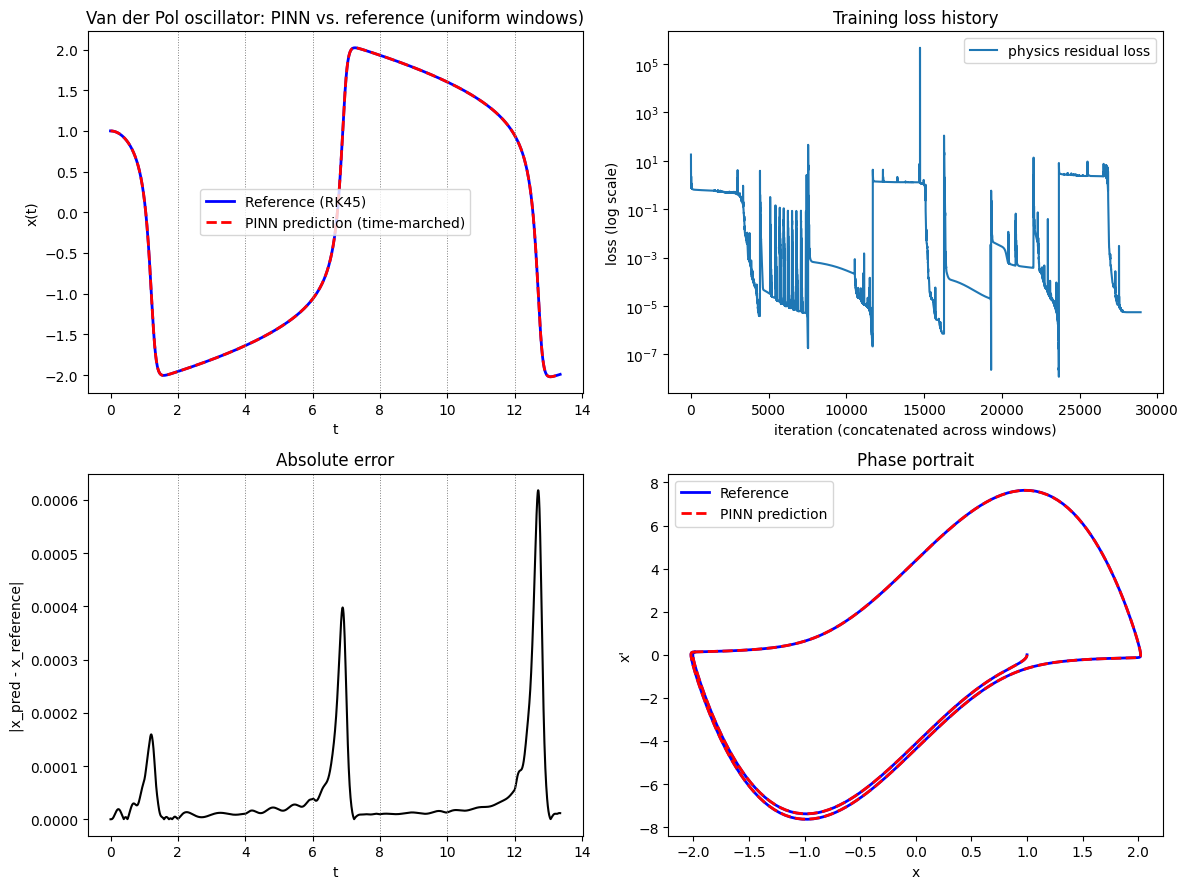

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].plot(t_eval, x_reference, "b-", linewidth=2, label="Reference (RK45)")
axes[0, 0].plot(t_eval, x_pred, "r--", linewidth=2, label="PINN prediction (time-marched)")
for edge in window_edges[1:-1]:
    axes[0, 0].axvline(edge, color="gray", linestyle=":", linewidth=0.7)
axes[0, 0].set_xlabel("t")
axes[0, 0].set_ylabel("x(t)")
axes[0, 0].set_title("Van der Pol oscillator: PINN vs. reference (uniform windows)")
axes[0, 0].legend()

axes[0, 1].semilogy(full_history, label="physics residual loss")
axes[0, 1].set_xlabel("iteration (concatenated across windows)")
axes[0, 1].set_ylabel("loss (log scale)")
axes[0, 1].set_title("Training loss history")
axes[0, 1].legend()

axes[1, 0].plot(t_eval, np.abs(x_pred - x_reference), "k-")
for edge in window_edges[1:-1]:
    axes[1, 0].axvline(edge, color="gray", linestyle=":", linewidth=0.7)
axes[1, 0].set_xlabel("t")
axes[1, 0].set_ylabel("|x_pred - x_reference|")
axes[1, 0].set_title("Absolute error")

x_pred_dot = np.gradient(x_pred, t_eval)
axes[1, 1].plot(x_reference, v_reference, "b-", linewidth=2, label="Reference")
axes[1, 1].plot(x_pred, x_pred_dot, "r--", linewidth=2, label="PINN prediction")
axes[1, 1].set_xlabel("x")
axes[1, 1].set_ylabel("x'")
axes[1, 1].set_title("Phase portrait")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("pinn_van_der_pol_window_results.png", dpi=150)
plt.show()